# ROD dataset exploration

Basic analysis of the ROD obstacle-detection dataset (YOLO format).

Run the cells in order. The dataset must already be downloaded with `download_rod.py`.

YOLO label format: one `.txt` per image, one line per object, all values normalized 0 to 1:
- box: `class_id x_center y_center width height`
- polygon (segmentation): `class_id x1 y1 x2 y2 ...`. Some ROD labels are polygons; Ultralytics converts them to boxes when training a detector, and this notebook does the same.

## 1. Settings

In [1]:
from pathlib import Path

# Folder that contains data.yaml and the train/valid/test folders
DATASET_DIR = Path("../../data/rod/ROD-Dataset/dataset").resolve()
SPLITS = ["train", "valid", "test"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print(DATASET_DIR, "exists:", DATASET_DIR.exists())

D:\My Projects\blind-guide\fast_path\object_detection\data\rod\ROD-Dataset\dataset exists: True


## 2. Imports

In [3]:
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from PIL import Image

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)

## 3. Class names (data.yaml)

In [4]:
with open(DATASET_DIR / "data.yaml", encoding="utf-8") as f:
    data_yaml = yaml.safe_load(f)

names = data_yaml["names"]
if isinstance(names, dict):  # YOLO also allows {id: name}
    names = [names[i] for i in sorted(names)]
print("nc =", data_yaml.get("nc"), "| names listed =", len(names))
pd.DataFrame({"class_id": range(len(names)), "class_name": names})

nc = 25 | names listed = 25


,class_id,class_name
0,0,Bike
1,1,Building
2,2,Car
3,3,Person
4,4,Stairs
5,5,Traffic sign
6,6,Electrical Pole
7,7,Road
8,8,Motorcycle
9,9,Dustbin


## 4. Load all labels into one table

`images` has one row per image, `boxes` has one row per box.

In [7]:
image_rows, box_rows, bad_lines = [], [], []

for split in SPLITS:
    image_dir = DATASET_DIR / split / "images"
    label_dir = DATASET_DIR / split / "labels"
    for image_path in sorted(image_dir.iterdir()):
        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue
        label_path = label_dir / f"{image_path.stem}.txt"
        n_boxes = 0
        if label_path.exists():
            for line_no, line in enumerate(label_path.read_text().splitlines(), 1):
                parts = line.split()
                if not parts:
                    continue
                cls = int(float(parts[0]))
                values = list(map(float, parts[1:]))
                if len(values) == 4:  # box: xc yc w h
                    xc, yc, w, h = values
                    label_type = "box"
                elif len(values) >= 6 and len(values) % 2 == 0:  # polygon: x1 y1 x2 y2 ...
                    xs, ys = values[0::2], values[1::2]  # Ultralytics turns these into boxes the same way
                    xc, yc = (min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2
                    w, h = max(xs) - min(xs), max(ys) - min(ys)
                    label_type = "polygon"
                else:
                    bad_lines.append((split, label_path.name, line_no, line))
                    continue
                box_rows.append({"split": split, "image": image_path.name, "class_id": cls,
                                 "xc": xc, "yc": yc, "w": w, "h": h, "label_type": label_type})
                n_boxes += 1
        image_rows.append({"split": split, "image": image_path.name, "path": str(image_path),
                           "has_label_file": label_path.exists(), "n_boxes": n_boxes})

images = pd.DataFrame(image_rows)
boxes = pd.DataFrame(box_rows)
boxes["class_name"] = boxes["class_id"].map(lambda i: names[i] if 0 <= i < len(names) else f"UNKNOWN_{i}")
boxes["area"] = boxes["w"] * boxes["h"]  # fraction of the image area

print(f"images: {len(images):,} | boxes: {len(boxes):,} | malformed label lines: {len(bad_lines)}")
print("\nLabel types (polygons are converted to their bounding box):")
print(boxes.groupby(["split", "label_type"]).size().unstack(fill_value=0).reindex(SPLITS))

images: 24,326 | boxes: 40,195 | malformed label lines: 0

Label types (polygons are converted to their bounding box):
label_type    box  polygon
split                     
train       28336     3915
valid        4764      808
test         1957      415


## 5. Split overview

In [6]:
split_summary = images.groupby("split").agg(
    images=("image", "count"),
    boxes=("n_boxes", "sum"),
    images_without_boxes=("n_boxes", lambda s: int((s == 0).sum())),
    missing_label_files=("has_label_file", lambda s: int((~s).sum())),
    mean_boxes_per_image=("n_boxes", "mean"),
    max_boxes_per_image=("n_boxes", "max"),
).reindex(SPLITS)
split_summary["share_of_images_%"] = 100 * split_summary["images"] / split_summary["images"].sum()
split_summary.round(2)

,images,boxes,images_without_boxes,missing_label_files,mean_boxes_per_image,max_boxes_per_image,share_of_images_%
split,,,,,,,
train,19186,28336,3503,0,1.48,94,78.87
valid,3511,4764,746,0,1.36,42,14.43
test,1629,1957,397,0,1.20,30,6.70


## 6. Boxes per class, per split

In [8]:
box_counts = boxes.pivot_table(index="class_name", columns="split", values="image",
                               aggfunc="count", fill_value=0).reindex(columns=SPLITS, fill_value=0)
box_counts["total"] = box_counts.sum(axis=1)
box_counts["share_%"] = (100 * box_counts["total"] / box_counts["total"].sum()).round(2)
box_counts = box_counts.sort_values("total", ascending=False)
box_counts

split,train,valid,test,total,share_%
class_name,,,,,
Person,7609,1033,320,8962,22.30
Car,4328,1003,247,5578,13.88
Manhole,1779,480,242,2501,6.22
Pedestrian crosswalk,1875,429,189,2493,6.20
Chair,1757,419,168,2344,5.83
Tree,1632,293,150,2075,5.16
Stairs,1125,339,223,1687,4.20
Guard rail,1385,131,69,1585,3.94
Dustbin,1351,153,45,1549,3.85


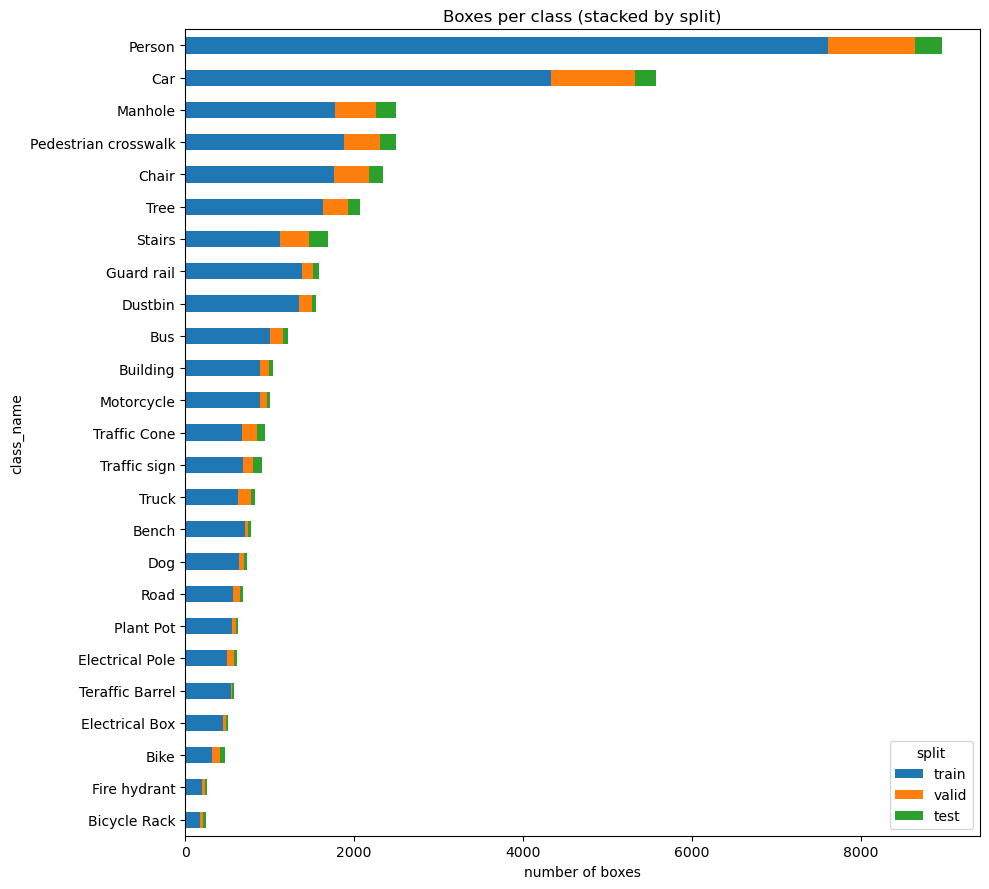

In [9]:
ax = box_counts[SPLITS].plot(kind="barh", stacked=True, figsize=(10, 9))
ax.invert_yaxis()
ax.set_xlabel("number of boxes")
ax.set_title("Boxes per class (stacked by split)")
plt.tight_layout()
plt.show()

## 7. Images containing each class, per split

One image with 5 cars counts once here (it counts 5 times in section 6).

In [10]:
image_counts = (boxes.drop_duplicates(["split", "image", "class_name"])
                .pivot_table(index="class_name", columns="split", values="image",
                             aggfunc="count", fill_value=0)
                .reindex(columns=SPLITS, fill_value=0))
image_counts["total"] = image_counts.sum(axis=1)
image_counts.sort_values("total", ascending=False)

split,train,valid,test,total
class_name,,,,
Car,2597,557,149,3303
Person,2377,347,88,2812
Manhole,1687,455,231,2373
Pedestrian crosswalk,1473,317,153,1943
Chair,1070,317,128,1515
Tree,1075,225,114,1414
Guard rail,1072,105,65,1242
Stairs,743,237,152,1132
Dustbin,967,99,27,1093


## 8. Split balance per class

Percentage of each class's boxes in train / valid / test. Overall the dataset is about 79 / 14 / 7. Classes far from that, or with very few test boxes, give unreliable test scores.

In [11]:
balance = (100 * box_counts[SPLITS].div(box_counts["total"], axis=0)).round(1)
balance["test_boxes"] = box_counts["test"]
balance["few_test_boxes(<30)"] = box_counts["test"] < 30
balance.sort_values("test_boxes")

split,train,valid,test,test_boxes,few_test_boxes(<30)
class_name,,,,,
Teraffic Barrel,93.8,3.0,3.3,19,True
Fire hydrant,80.4,9.8,9.8,25,True
Bench,91.2,5.2,3.6,28,True
Dog,87.0,8.9,4.1,30,False
Plant Pot,88.7,5.9,5.4,34,False
Electrical Box,87.7,5.7,6.6,34,False
Bicycle Rack,69.7,15.6,14.8,36,False
Motorcycle,88.2,8.1,3.7,37,False
Road,82.3,12.3,5.4,37,False


## 9. Boxes per image

         count  mean   std  min  25%  50%  75%   max
split                                               
train  19186.0  1.68  2.65  0.0  1.0  1.0  1.0  94.0
valid   3511.0  1.59  1.84  0.0  1.0  1.0  1.0  42.0
test    1629.0  1.46  1.68  0.0  1.0  1.0  1.0  30.0


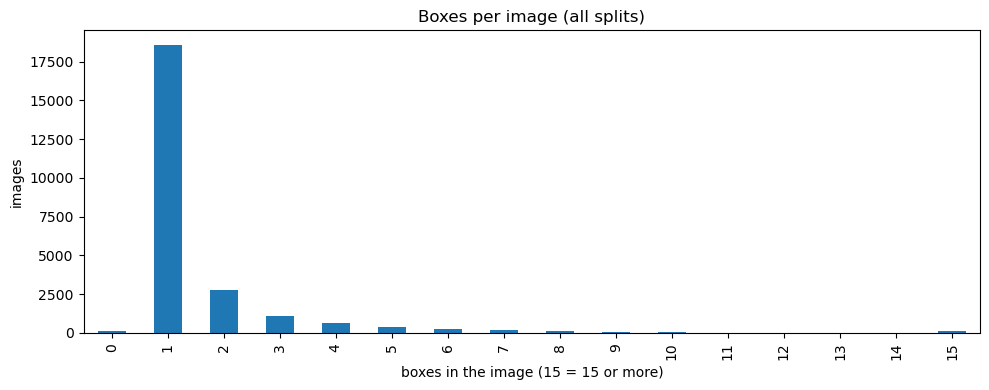

In [12]:
print(images.groupby("split")["n_boxes"].describe().reindex(SPLITS).round(2))

max_shown = 15
clipped = images["n_boxes"].clip(upper=max_shown)
ax = clipped.value_counts().sort_index().plot(kind="bar", figsize=(10, 4))
ax.set_xlabel(f"boxes in the image ({max_shown} = {max_shown} or more)")
ax.set_ylabel("images")
ax.set_title("Boxes per image (all splits)")
plt.tight_layout()
plt.show()

## 10. Box sizes

`area` = box area as a fraction of the image. Size buckets (relative to the image): small < 1%, medium 1 to 10%, large > 10%. Small objects are the hardest for a nano model.

In [13]:
boxes["size"] = pd.cut(boxes["area"], bins=[0, 0.01, 0.10, 1.0001],
                       labels=["small(<1%)", "medium(1-10%)", "large(>10%)"], include_lowest=True)
size_table = boxes.pivot_table(index="class_name", columns="size", values="image",
                               aggfunc="count", fill_value=0, observed=False)
size_table["median_area_%"] = (100 * boxes.groupby("class_name")["area"].median()).round(2)
size_table.sort_values("median_area_%")

size,small(<1%),medium(1-10%),large(>10%),median_area_%
class_name,,,,
Person,2203,3424,3335,4.83
Traffic sign,166,222,519,14.03
Plant Pot,3,230,398,17.02
Traffic Cone,17,262,662,17.06
Electrical Pole,8,171,439,19.96
Fire hydrant,0,27,228,21.01
Bicycle Rack,0,43,201,21.34
Bus,169,330,715,21.94
Motorcycle,27,338,642,23.11


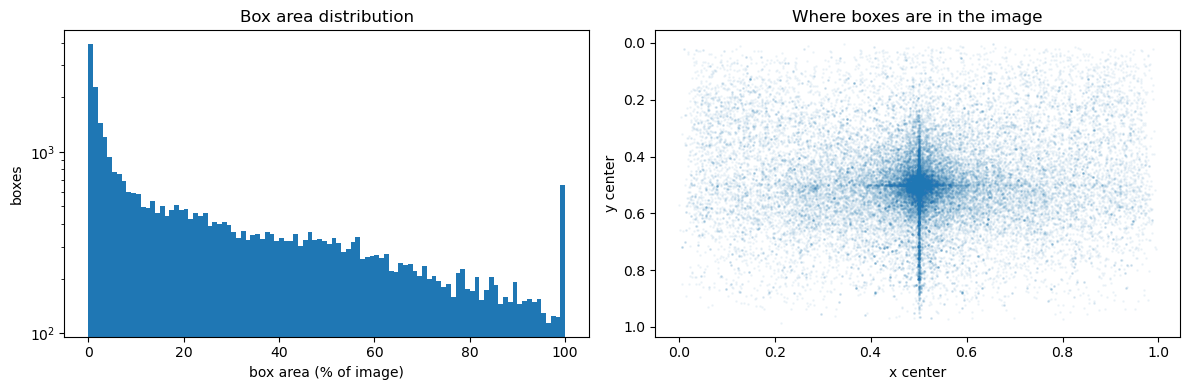

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(boxes["area"] * 100, bins=100)
axes[0].set_xlabel("box area (% of image)")
axes[0].set_ylabel("boxes")
axes[0].set_yscale("log")
axes[0].set_title("Box area distribution")
axes[1].scatter(boxes["xc"], boxes["yc"], s=1, alpha=0.05)
axes[1].invert_yaxis()
axes[1].set_xlabel("x center")
axes[1].set_ylabel("y center")
axes[1].set_title("Where boxes are in the image")
plt.tight_layout()
plt.show()

## 11. Image resolutions

Reads only image headers (fast).

In [15]:
def image_size(path):
    try:
        with Image.open(path) as im:
            return im.size  # (width, height)
    except Exception:
        return (None, None)

images[["width", "height"]] = pd.DataFrame(images["path"].map(image_size).tolist(), index=images.index)
images["resolution"] = images["width"].astype("Int64").astype(str) + "x" + images["height"].astype("Int64").astype(str)
images["aspect"] = (images["width"] / images["height"]).round(2)
print("unreadable images:", int(images["width"].isna().sum()))
print("\nTop resolutions:")
print(images["resolution"].value_counts().head(15))
print("\nAspect ratio (width / height):")
print(images["aspect"].value_counts().head(10))

unreadable images: 0

Top resolutions:
resolution
640x640      17634
416x416       3421
512x512        980
300x300        873
640x480        645
434x327         25
259x194         22
1024x768        20
344x289         12
600x400         11
800x600         10
480x360          9
1600x1200        9
500x333          9
400x300          8
Name: count, dtype: int64

Aspect ratio (width / height):
aspect
1.00    22911
1.33      783
1.50       82
1.51       37
1.34       33
1.60       31
1.49       18
1.64       17
1.78       16
1.68       16
Name: count, dtype: int64


## 12. Label sanity checks

In [16]:
checks = {
    "malformed lines (not a box or polygon)": len(bad_lines),
    "class id out of range": int((~boxes["class_id"].between(0, len(names) - 1)).sum()),
    "coordinates outside [0, 1]": int(((boxes[["xc", "yc", "w", "h"]] < 0) | (boxes[["xc", "yc", "w", "h"]] > 1)).any(axis=1).sum()),
    "zero or negative width/height": int(((boxes["w"] <= 0) | (boxes["h"] <= 0)).sum()),
    "tiny boxes (< 0.01% of image)": int((boxes["area"] < 0.0001).sum()),
    "exact duplicate boxes in the same image": int(boxes.duplicated(["split", "image", "class_id", "xc", "yc", "w", "h"]).sum()),
    "images without a label file": int((~images["has_label_file"]).sum()),
}
pd.Series(checks, name="count")

malformed lines (not a box or polygon)      0
class id out of range                       0
coordinates outside [0, 1]                  0
zero or negative width/height               0
tiny boxes (< 0.01% of image)              12
exact duplicate boxes in the same image     0
images without a label file                 0
Name: count, dtype: int64

## 13. Exact duplicate images and split leakage

Hashes every image file (takes a minute). The same file in train and test would inflate test scores. This only finds byte-identical files, not near-duplicates (resized or re-encoded copies).

In [17]:
def file_md5(path):
    return hashlib.md5(Path(path).read_bytes()).hexdigest()

images["md5"] = images["path"].map(file_md5)
dup_groups = images[images.duplicated("md5", keep=False)].groupby("md5")
print("duplicate groups:", dup_groups.ngroups, "| images involved:", int(images.duplicated("md5", keep=False).sum()))

cross_split = dup_groups["split"].agg(lambda s: "+".join(sorted(set(s))))
print("\nDuplicate groups by which splits they span:")
print(cross_split.value_counts())

duplicate groups: 353 | images involved: 823

Duplicate groups by which splits they span:
split
train          259
train+valid     54
valid           17
test+train      14
test+valid       9
Name: count, dtype: int64


## 14. Extra files shipped with the dataset

Shows any CSV files (metadata, class distribution, etc.) found in the dataset folders.

In [18]:
for csv_path in sorted(DATASET_DIR.parent.rglob("*.csv")):
    df = pd.read_csv(csv_path)
    print(f"\n=== {csv_path.relative_to(DATASET_DIR.parent)}  ({len(df):,} rows) ===")
    print("columns:", list(df.columns))
    display(df.head(5))


=== dataset\class_distribution.csv  (26 rows) ===
columns: ['class_id', 'class_name', 'train', 'valid', 'test', 'total']


,class_id,class_name,train,valid,test,total
0,0.0,Bike,323,95,49,467
1,1.0,Building,886,101,54,1041
2,2.0,Car,4328,1003,247,5578
3,3.0,Person,7609,1033,320,8962
4,4.0,Stairs,1125,339,223,1687



=== dataset\images_manifest.csv  (24,326 rows) ===
columns: ['split', 'image_filename', 'label_filename', 'num_objects', 'classes_present', 'class_names_present']


,split,image_filename,label_filename,num_objects,classes_present,class_names_present
0,train,IMG_00001.jpg,IMG_00001.txt,1,2,Car
1,train,IMG_00002.jpg,IMG_00002.txt,1,2,Car
2,train,IMG_00003.jpg,IMG_00003.txt,2,2,Car
3,train,IMG_00004.jpg,IMG_00004.txt,1,2,Car
4,train,IMG_00005.jpg,IMG_00005.txt,1,2,Car



=== dataset\rename_map.csv  (24,326 rows) ===
columns: ['split', 'old_stem', 'new_stem', 'image_ext']


,split,old_stem,new_stem,image_ext
0,train,-0378D390-5AE2-4D09-84BB-387E850F5E5A-png_jpg....,IMG_00001,.jpg
1,train,-0378D390-5AE2-4D09-84BB-387E850F5E5A-png_jpg....,IMG_00002,.jpg
2,train,-046E9840-F025-4749-B3AB-19402B34E739-png_jpg....,IMG_00003,.jpg
3,train,-0471C451-8CA5-4CEA-8EFD-3B0F147BF4B7-png_jpg....,IMG_00004,.jpg
4,train,-0585CFA0-7CD6-45D3-B7EB-1A109425F90D-png_jpg....,IMG_00005,.jpg


## 15. Random example images (manual check)

Shows `N_EXAMPLES` random images with their boxes; new random images on every run.
- `CLASS_TO_SHOW = None`: any image (all classes). Set a name (e.g. `"Stairs"`) to only pick images with that class; its boxes are drawn in red, others in green.
- `SPLIT_TO_SHOW = None`: all splits, or `"train"` / `"valid"` / `"test"`.
- `INCLUDE_EMPTY = True`: also allow background images that have no boxes (only when `CLASS_TO_SHOW` is None).

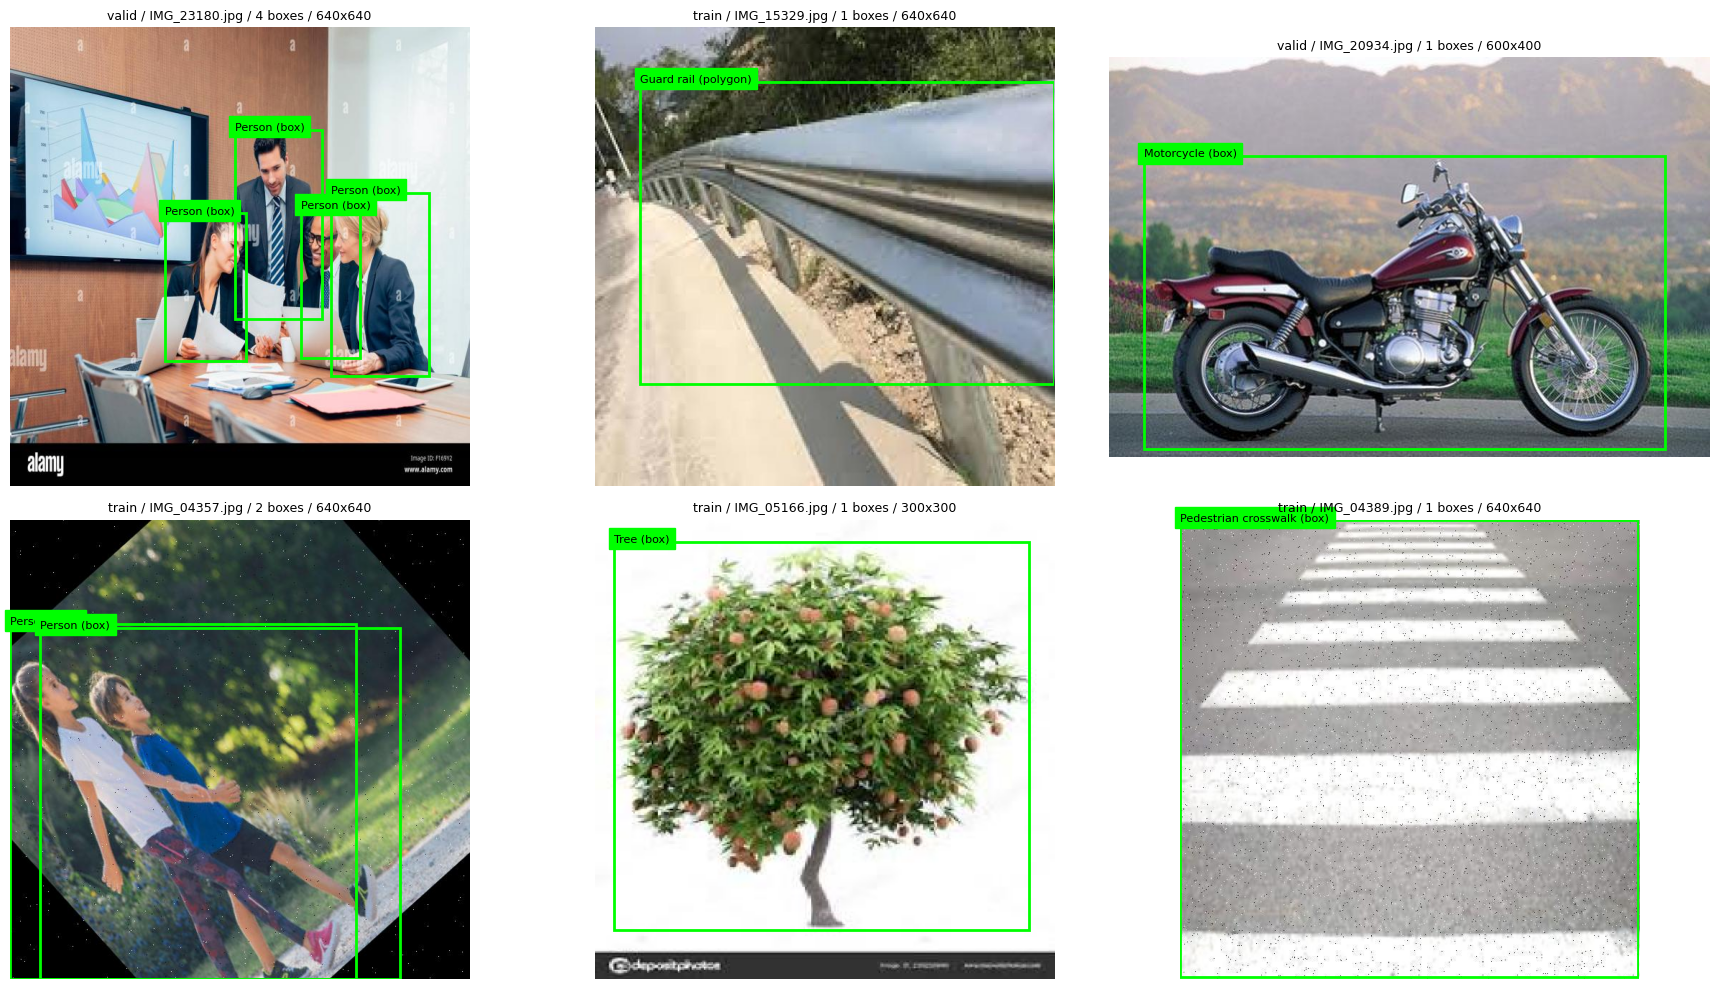

In [50]:
CLASS_TO_SHOW = None  # None = all classes, or a class name from section 3
SPLIT_TO_SHOW = None  # None = all splits, or "train" / "valid" / "test"
N_EXAMPLES = 6
INCLUDE_EMPTY = True

pool = images.copy()
if SPLIT_TO_SHOW:
    pool = pool[pool["split"] == SPLIT_TO_SHOW]
if CLASS_TO_SHOW:
    with_class = boxes.loc[boxes["class_name"] == CLASS_TO_SHOW, ["split", "image"]].drop_duplicates()
    pool = pool.merge(with_class, on=["split", "image"])
elif not INCLUDE_EMPTY:
    pool = pool[pool["n_boxes"] > 0]
chosen = pool.sample(min(N_EXAMPLES, len(pool)))  # no random_state: different images every run

cols = 3
rows = max(1, int(np.ceil(len(chosen) / cols)))
fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 5 * rows))
for ax in np.ravel(axes):
    ax.axis("off")
for ax, (_, row) in zip(np.ravel(axes), chosen.iterrows()):
    im = Image.open(row["path"]).convert("RGB")
    W, H = im.size
    ax.imshow(im)
    image_boxes = boxes[(boxes["split"] == row["split"]) & (boxes["image"] == row["image"])]
    for _, b in image_boxes.iterrows():
        x1, y1 = (b["xc"] - b["w"] / 2) * W, (b["yc"] - b["h"] / 2) * H
        color = "red" if b["class_name"] == CLASS_TO_SHOW else "lime"
        ax.add_patch(plt.Rectangle((x1, y1), b["w"] * W, b["h"] * H, fill=False, color=color, lw=2))
        ax.text(x1, y1, f"{b['class_name']} ({b['label_type']})", color="black", fontsize=8, backgroundcolor=color)
    ax.set_title(f"{row['split']} / {row['image']} / {len(image_boxes)} boxes / {W}x{H}", fontsize=9)
plt.tight_layout()
plt.show()